在 PyCharm 打开本项目后，在窗口右下角添加解释器：添加新的解释器 -> 添加本地解释器 -> 环境：选择现有 -> 类型：Conda -> 环境：lidar（在前期准备中配置好的环境）

In [7]:
# 打开代码后，Tools 文件就在同目录下，所以不用设置 Tools 路径
from Tools.ReadPointCloud import *
import open3d as o3d
from Tools.Treeseg import WatershedSeg
from Tools.Down_Sample import *
from Tools.GroundSegment import *
from Tools.Clean import *
from Tools.Treeseg import *
from Tools.TLS2tree import TLSSeg,MergePoint
from lewos import lewos
import os
import numpy as np

导入数据：

In [2]:
# 点云数据路径
datapth = r"..\Data\BLK_small.laz"
spth = r'.\Output'

# 基于 laspy 读取点云，并转成 open3D 格式
las = ReadPointCloud(datapth)
pcd = laspy2o3d(las)

Read point cloud: ..\Data\BLK_small.laz


点云抽析（下采样）

**注意 `o3d.io.write_point_cloud` 不能覆盖写入，重新运行时需要先将原文件删除。**

In [3]:
# 点云下采样，单位 m
voxel_size = 0.02
pcd_down_sample = voxel_down_sample(pcd, voxel_size=voxel_size)
o3d.io.write_point_cloud(os.path.join(spth,'Down_sample.pcd'), pcd_down_sample)

Point Cloud Subsample: 0.02


True

点云去噪：
- **方法一** 球形边界去噪 `radius_outlier_removal`
  - `nb_points`：邻居点数阈值
  - `radius`：检测球体半径
- **方法二** 统计学方法去噪 `statistical_outlier_removal`
  - `neighbors`：每个点周围检测的临近点数
  - `ratio`：几倍标准差

In [4]:
# 方法一
pcd_radius_outlier, pcd_radius_inlier = radius_outlier_removal(pcd_down_sample, nb_points=5, radius=0.1)
o3d.io.write_point_cloud(os.path.join(spth,'pcd_radius_outlier.pcd'), pcd_radius_outlier)
o3d.io.write_point_cloud(os.path.join(spth,'pcd_radius_inlier.pcd'), pcd_radius_inlier)

Set outliers (red) and inliers (gray)
----outlier_cloud:  std::vector<Eigen::Vector3d> with 22099 elements.
Use numpy.asarray() to access data.
----inlier_cloud:  std::vector<Eigen::Vector3d> with 3744825 elements.
Use numpy.asarray() to access data.


True

In [5]:
# 方法二
pcd_statistical_outlier, pcd_statistical_inlier = statistical_outlier_removal(pcd_down_sample, neighbors=5, ratio=10.0)
o3d.io.write_point_cloud(os.path.join(spth,'pcd_stats_outlier.pcd'), pcd_statistical_outlier)
o3d.io.write_point_cloud(os.path.join(spth,'pcd_stats_inlier.pcd'), pcd_statistical_inlier)

Set outliers (red) and inliers (gray)
----outlier_cloud:  std::vector<Eigen::Vector3d> with 2231 elements.
Use numpy.asarray() to access data.
----inlier_cloud:  std::vector<Eigen::Vector3d> with 3764693 elements.
Use numpy.asarray() to access data.


True

地面点分离，先提取 z 值最低点，再对这些点采用泊松表面重建算法拟合地面。
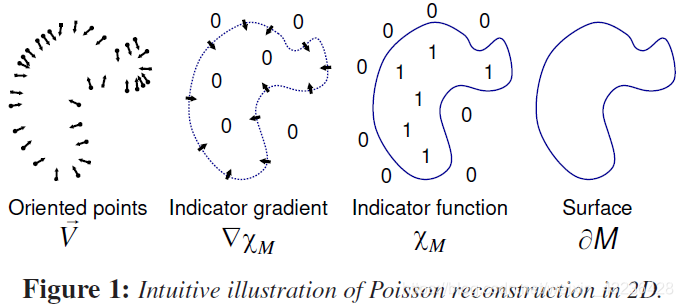

In [8]:
# 如果之前的结果在重启 kernel 之后消失了，就需要重新读入
# 选择用 pcd_statistical_inlier 或者 pcd_radius_inlier 都可以
# pcd_radius_inlier = o3d.io.read_point_cloud(os.path.join(spth,'pcd_radius_inlier.pcd'))
# pcd_statistical_inlier = o3d.io.read_point_cloud(os.path.join(spth,'pcd_stats_inlier.pcd'))

# ground, aboveground = PlaneSegmentation(pcd)  # 直接拟合点云中的平面并分割，我们一般不使用这种方法寻找地面点
ground, aboveground = PoissonSurfaceFilter(pcd_radius_inlier, pillar_size=1, threshold=0.3)  # 寻找最低点 + 泊松表面重建算法
o3d.io.write_point_cloud(os.path.join(spth,'ground.pcd'), ground)
o3d.io.write_point_cloud(os.path.join(spth,'aboveground.pcd'), aboveground)

Find the lowest point in pillars
run Poisson surface reconstruction
[Open3D DEBUG] Input Points / Samples: 73 / 73
[Open3D DEBUG] #   Got kernel density: 0.002000093460083008 (s), 2097.69921875 (MB) / 2117.9140625 (MB) / 3359 (MB)
[Open3D DEBUG] #     Got normal field: 0 (s), 2097.69921875 (MB) / 2117.9140625 (MB) / 3359 (MB)
[Open3D DEBUG] Point weight / Estimated Area: 1.643385e-02 / 1.199671e+00
[Open3D DEBUG] #       Finalized tree: 0.007999897003173828 (s), 2100 (MB) / 2117.9140625 (MB) / 3359 (MB)
[Open3D DEBUG] #  Set FEM constraints: 0.026999950408935547 (s), 2099.328125 (MB) / 2117.9140625 (MB) / 3359 (MB)
[Open3D DEBUG] #Set point constraints: 0.0010001659393310547 (s), 2099.328125 (MB) / 2117.9140625 (MB) / 3359 (MB)
[Open3D DEBUG] Leaf Nodes / Active Nodes / Ghost Nodes: 79304 / 66888 / 23745
[Open3D DEBUG] Memory Usage: 2099.328 MB
[Open3D DEBUG] # Linear system solved: 0.07299995422363281 (s), 2101.40625 (MB) / 2117.9140625 (MB) / 3359 (MB)
[Open3D DEBUG] Got average: 0.0

True

利用 LeWoS 算法进行枝叶分离。在 PyCharm 终端里运行：

```
cd .\BLK
python run_lewos.py
```

单木分割：

In [ ]:
import sys
sys.argv = ['']

pcd = MergePoint(groundpth=os.path.join(spth,'ground.pcd'),leafwoodpth=os.path.join(spth,'leaf_wood.txt'))
TLSSeg(pcd,spth)


##点云可视化
# o3d.visualization.draw_geometries([ground, aboveground])
# o3d.io.write_point_cloud(spth, data)